# Supervised Learning - Deep Neural Networks
- Python program to recognise hand-written digits using a basic neural network and a convolutional neural network (CNN).
- The MNIST dataset is used.

In [19]:
"""
@author: Apoorva Upadhyay

Thanks to keras documentation.
"""



'\nCreated on Tue Aug  1 15:59:08 2023\n\n@author: Apoorva Upadhyay\n\nThanks to keras documentation.\n'

## Basic neural network

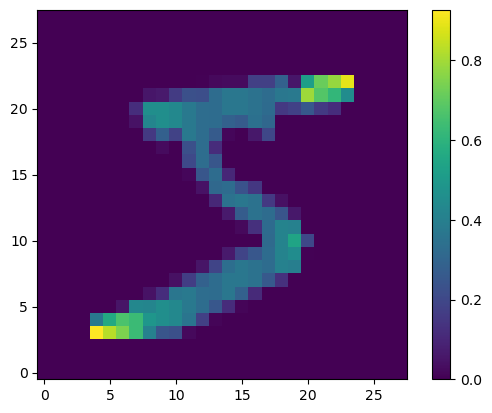

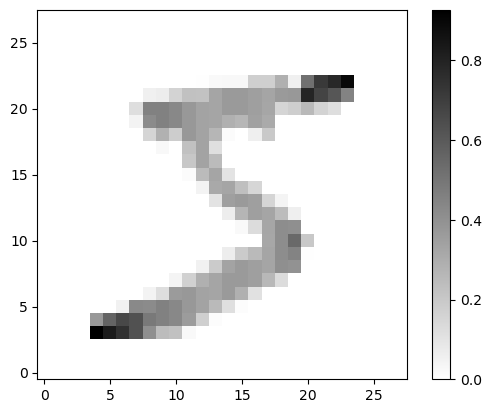

digit pixel size NxN (28, 28)
Train on 60000 samples
Epoch 1/3
60000/60000 - 8s - loss: 0.3193 - accuracy: 0.9026
Epoch 2/3
60000/60000 - 6s - loss: 0.2165 - accuracy: 0.9352
Epoch 3/3
60000/60000 - 6s - loss: 0.1992 - accuracy: 0.9402
10000/1 [===================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================

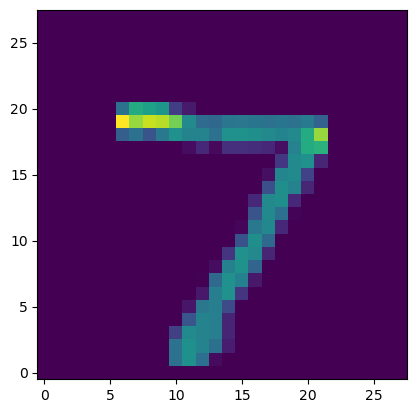

10000/1 [===============================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================

In [20]:
#############################################################################
# Basic neural network

import tensorflow as tf
import cv2
import matplotlib.pyplot as plt
import numpy as np

mnist = tf.keras.datasets.mnist # 28x28 pixel digits

(x_train, y_train), (x_test, y_test) = mnist.load_data()

x_train = tf.keras.utils.normalize(x_train, axis=1)
x_test = tf.keras.utils.normalize(x_test, axis=1)

# flip digit images and so we can plot normally
for i in range(len(x_train)):
    x_train[i] = cv2.flip(x_train[i], 0)
    
for i in range(len(x_test)):
    x_test[i] = cv2.flip(x_test[i], 0)

plt.imshow(x_train[0],interpolation='nearest',origin='lower')
plt.axis()
plt.colorbar()
plt.show()

plt.imshow(x_train[0],interpolation='nearest',origin='lower', cmap=plt.cm.binary)
plt.axis()
plt.colorbar()
plt.show()

(M,N)= np.shape(x_train[0])
print('digit pixel size NxN', np.shape(x_train[0]))

# create input array...hmm

x_train_list = []

for i in range(len(x_train)):
    x_train_list.append(x_train[i])
    
x_train_list_array = np.array(x_train_list)
########################################
# network build, train

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Activation, Dense, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import categorical_crossentropy

modelMNIST = Sequential([
    
    Flatten(), # not sure how Flatten() works exactly
    #Dense(units=16, input_shape=(M,M,1), activation="relu"),
    Dense(units=16, activation="relu"),
    Dense(units=32, activation="relu"),
    Dense(units=10, activation="softmax")
    
                    
                    
                    ])


#print(model.summary)

########################################
# model compile and train

modelMNIST.compile(optimizer=Adam(learning_rate=0.01), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

#modelMNIST.fit(x=x_train, y=y_train, batch_size=300, epochs=3, shuffle=True, verbose=2)
modelMNIST.fit(x=x_train, y=y_train, epochs=3, shuffle=True, verbose=2)

# batchsize here would mean number of digit images passed through network for trainging per epoch?
########################################

val_loss, val_acc = modelMNIST.evaluate(x_test, y_test)
print(val_loss, val_acc)

########################################

modelMNIST.save('modelMNIST_SimpleNN.model') # accuracy 93.14% on training data

########################################

new_modelMNIST = tf.keras.models.load_model('modelMNIST_SimpleNN.model')

predictions = new_modelMNIST.predict([x_test])

print('prediction:',np.argmax(predictions[0]))

plt.imshow(x_test[0],interpolation='nearest',origin='lower')
plt.show()

val_loss, val_acc = new_modelMNIST.evaluate(x_test, y_test)
print(val_loss, val_acc)

## Convolutional Neural Network (CNN)

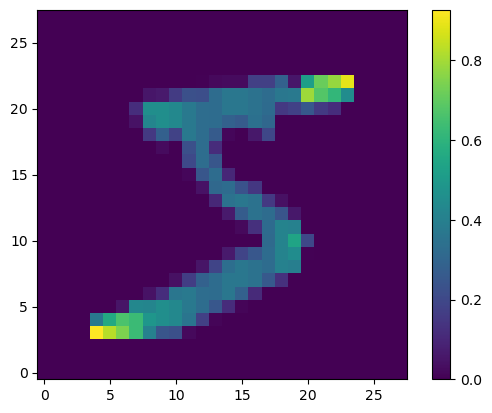

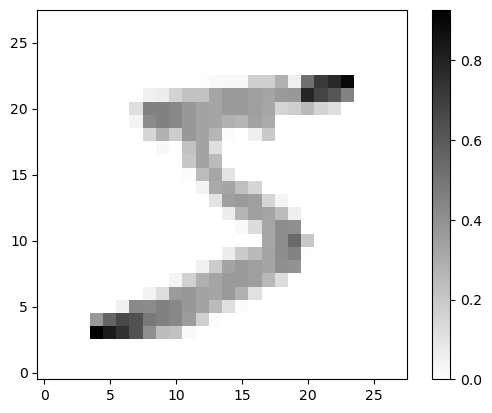

digit pixel size NxN (28, 28)


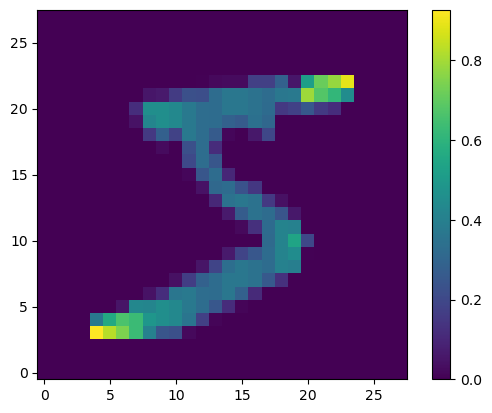

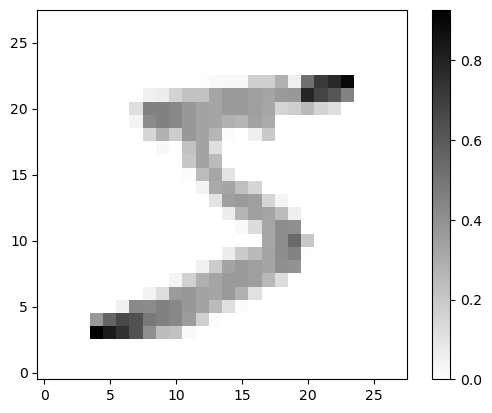

Train on 60000 samples
Epoch 1/3
60000/60000 - 30s - loss: 0.1665 - accuracy: 0.9507
Epoch 2/3
60000/60000 - 30s - loss: 0.0811 - accuracy: 0.9748
Epoch 3/3
60000/60000 - 28s - loss: 0.0627 - accuracy: 0.9804
INFO:tensorflow:Assets written to: modelMNIST_CNN.model/assets
prediction: 7


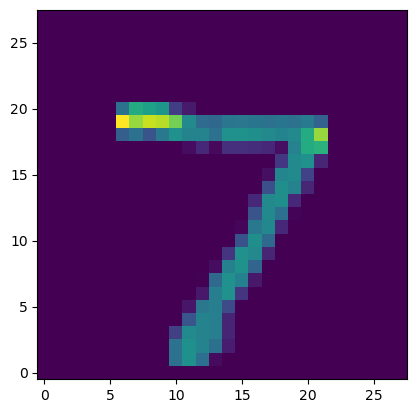


10000/1 [==============================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================================

0.11657781131519004 0.9706


In [5]:
# 2 CNN

import tensorflow as tf
import cv2
import matplotlib.pyplot as plt
import numpy as np

mnist = tf.keras.datasets.mnist # 28x28 pixel digits

(x_train, y_train), (x_test, y_test) = mnist.load_data()

x_train = tf.keras.utils.normalize(x_train, axis=1)
x_test = tf.keras.utils.normalize(x_test, axis=1)

# flip digit images and so we can plot normally
for i in range(len(x_train)):
    x_train[i] = cv2.flip(x_train[i], 0)
    
for i in range(len(x_test)):
    x_test[i] = cv2.flip(x_test[i], 0)

plt.imshow(x_train[0],interpolation='nearest',origin='lower')
plt.axis()
plt.colorbar()
plt.show()

plt.imshow(x_train[0],interpolation='nearest',origin='lower', cmap=plt.cm.binary)
plt.axis()
plt.colorbar()
plt.show()

(M,N)= np.shape(x_train[0])
print('digit pixel size NxN', np.shape(x_train[0]))

########################################
# CNN network build, train

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Activation, Dense, Flatten, BatchNormalization, Conv2D, MaxPool2D, AveragePooling2D, Convolution2D, InputLayer
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import categorical_crossentropy
from tensorflow.keras.preprocessing.image import ImageDataGenerator

##########################
(x_train_save, y_train_save), (x_test_save, y_test_save) = mnist.load_data()

np.savez('x_train_mnist.npz', *x_train_save)
np.savez('y_train_mnist.npz', *y_train_save)
np.savez('x_test_mnist.npz', *x_test_save)
np.savez('y_test_mnist.npz', *y_test_save)

########################################
# LOAD MNIST FROM FILE

container1 = np.load('x_train_mnist.npz')
x_train = [container1[key] for key in container1]

container2 = np.load('y_train_mnist.npz')
y_train = [container2[key] for key in container2]

container3 = np.load('x_test_mnist.npz')
x_test = [container3[key] for key in container3]

container4 = np.load('y_test_mnist.npz')
y_test = [container4[key] for key in container4]



y_train = (np.array(y_train)).reshape(60000,)
y_test = (np.array(y_test)).reshape(10000,)


#########################

x_train = tf.keras.utils.normalize(x_train, axis=1)
x_test = tf.keras.utils.normalize(x_test, axis=1)

# flip digit images and so we can plot normally
for i in range(len(x_train)):
    x_train[i] = cv2.flip(x_train[i], 0)
    
for i in range(len(x_test)):
    x_test[i] = cv2.flip(x_test[i], 0)

plt.imshow(x_train[0],interpolation='nearest',origin='lower')
plt.axis()
plt.colorbar()
plt.show()

plt.imshow(x_train[0],interpolation='nearest',origin='lower', cmap=plt.cm.binary)
plt.axis()
plt.colorbar()
plt.show()

########################################

M = 28

#x_train = x_train.reshape(60000,28,28,1)

#x_train = x_train.reshape(-1, 28 * 28)

x_train = np.expand_dims(x_train, axis=-1)  # (60000, 28, 28, 1)
x_test = np.expand_dims(x_test, axis=-1)  # (60000, 28, 28, 1)

modelMNIST_CNN = Sequential()
modelMNIST_CNN.add(Input(shape=(28,28,1)))
modelMNIST_CNN.add(Conv2D(filters=32,kernel_size=(3,3),activation='relu',padding='same'))
modelMNIST_CNN.add(Flatten())
modelMNIST_CNN.add(Dense(10, activation='softmax'))

########################################

modelMNIST_CNN.compile(optimizer=Adam(learning_rate=0.01), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

modelMNIST_CNN.fit(x=x_train, y=y_train, epochs=3, shuffle=True, verbose=2)


########################################

modelMNIST_CNN.save('modelMNIST_CNN.model') #accuracy 98.14% on training data

########################################
#val_loss, val_acc = modelMNIST_CNN.evaluate(x_test, y_test)
#print(val_loss, val_acc)

########################################

new_modelMNIST_CNN = tf.keras.models.load_model('modelMNIST_CNN.model')

predictions = new_modelMNIST_CNN.predict([x_test])
#predictions = new_modelMNIST_CNN.predict([x_train])


print('prediction:',np.argmax(predictions[0]))

plt.imshow(x_test[0,:,:,0],interpolation='nearest',origin='lower')
plt.show()

val_loss, val_acc = new_modelMNIST_CNN.evaluate(x_test, y_test)
print(val_loss, val_acc)

## Conclusion
- Basic neural network accuracy = 93%
- CNN accuracy = 97%